In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import numpy as np
from qiskit.quantum_info import hellinger_fidelity
import ast

In [2]:


def parse_csv_results(base_dir):
    data_frames = []

    for emulator_dir in os.listdir(base_dir):
        results_dir = os.path.join(base_dir, emulator_dir, 'results')
        if os.path.isdir(results_dir):
            for result_file in os.listdir(results_dir):
                if result_file.endswith('.csv'):
                    file_path = os.path.join(results_dir, result_file)
                    df = pd.read_csv(file_path)
                    data_frames.append(df)

    # Concatenate all data frames
    combined_df = pd.concat(data_frames, ignore_index=True)
    return combined_df

def plot_scaling(df):
    plt.figure(figsize=(14, 6))

    # Define line styles for single_node and two_node
    line_styles = {
        1: 'solid',  # Solid line for single_node
        2: 'dashed'      # Dashed line for two_node
    }

    # Define colors for each emulator
    colors = plt.cm.tab10(range(len(df['Emulator'].unique())))

    # Plot Execution Time Scaling
    plt.subplot(1, 2, 1)
    for (emulator, nodes), group_df in df.groupby(['Emulator', 'Nodes']):
        color = colors[df['Emulator'].unique().tolist().index(emulator)]
        plt.plot(group_df['Num Qubits'], group_df['Execution Time (s)'],
                 label=f'{emulator} ({nodes})', linestyle=line_styles[nodes], color=color, marker='o')
    plt.xlabel('Number of Qubits')
    plt.ylabel('Execution Time (s)')
    plt.title('Execution Time Scaling')
    plt.legend()

    # Plot Memory Usage Scaling
    plt.subplot(1, 2, 2)
    for (emulator, nodes), group_df in df.groupby(['Emulator', 'Nodes']):
        color = colors[df['Emulator'].unique().tolist().index(emulator)]
        plt.plot(group_df['Num Qubits'], group_df['Peak Memory (KB)'],
                 label=f'{emulator} ({nodes})', linestyle=line_styles[nodes], color=color, marker='o')
    plt.xlabel('Number of Qubits')
    plt.ylabel('Peak Memory Usage (KB)')
    plt.title('Memory Usage Scaling')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Base directory containing the emulators
base_dir = "emulators"

# Parse results and plot scaling
df = parse_csv_results(base_dir)


In [3]:
from datetime import datetime

timestamp = datetime.now().strftime("%Y%m%d")

# Save the DataFrame to a CSV file with a timestamp in the filename
output_file = f"results_analysis/results_analysis_{timestamp}.csv"
df.to_csv(output_file, index=False)

print(f"DataFrame saved to {output_file}")

DataFrame saved to results_analysis/results_analysis_20250730.csv


In [5]:
df

,Emulator,Nodes,Num Qubits,Theta,Shots,Execution Time (s),Current Memory (KB),Peak Memory (KB),Result
0,squidasm,1,4,0.00,100,4.819283,1.064394e+03,1.261888e+03,"{0.0: 21, 0.0625: 12, 0.125: 14, 0.1875: 2, 0...."
1,squidasm,1,4,0.66,100,5.375981,1.014110e+03,1.293396e+03,"{0.0: 6, 0.0625: 3, 0.125: 3, 0.1875: 4, 0.312..."
2,squidasm,1,4,0.33,100,5.458702,1.013685e+03,1.292747e+03,"{0.0: 2, 0.0625: 7, 0.125: 5, 0.1875: 3, 0.25:..."
3,squidasm,1,6,0.00,100,11.652005,1.372160e+03,1.734527e+03,"{0.0: 5, 0.015625: 3, 0.03125: 3, 0.0625: 4, 0..."
4,squidasm,1,6,0.66,100,12.194018,1.386354e+03,1.780423e+03,"{0.046875: 3, 0.0625: 1, 0.125: 1, 0.140625: 3..."
...,...,...,...,...,...,...,...,...,...
65,squidasm,1,20,0.66,100,3117.861390,7.109981e+06,7.177792e+06,"{0.009337425231933594: 1, 0.010898590087890625..."
66,squidasm,1,20,0.33,100,3144.084276,7.109981e+06,7.177792e+06,"{0.01766490936279297: 1, 0.05526447296142578: ..."
67,squidasm,2,20,0.66,100,7752.992536,7.117246e+06,7.372934e+06,"{0.015893936157226562: 1, 0.032835960388183594..."
68,squidasm,2,20,0.33,100,7772.464775,7.347883e+06,7.609716e+06,"{0.010698318481445312: 1, 0.015036582946777344..."


In [6]:
def aermemory(n):
    return 8*2**(n+1)/1024

In [7]:
def plot_scaling_vs_qubits(
    df,
    log_scale=True,
    save_path=None,
    figsize=(14, 6),
    title_suffix=""
):
    """
    Plot execution time and memory as a function of number of qubits,
    using color to indicate number of nodes and marker+linestyle for emulator.
    """
    import matplotlib.pyplot as plt

    plt.figure(figsize=figsize)

    emulators = sorted(df["Emulator"].unique())
    nodes_list = sorted(df["Nodes"].unique())

    colors = {n: plt.cm.viridis(i / max(nodes_list)) for i, n in enumerate(nodes_list)}
    markers = ['o', 's', 'D', 'x', '^', 'v']
    linestyles = ['solid', 'dashed', 'dashdot', 'dotted']

    emulator_styles = {
        emu: (markers[i % len(markers)], linestyles[i % len(linestyles)])
        for i, emu in enumerate(emulators)
    }

    # --- Execution Time
    plt.subplot(1, 2, 1)
    for (emulator, nodes), group_df in df.groupby(['Emulator', 'Nodes']):
        marker, linestyle = emulator_styles[emulator]
        color = colors[nodes]
        group_sorted = group_df.sort_values("Num Qubits")

        plt.plot(group_sorted["Num Qubits"], group_sorted["Execution Time (s)"],
                 label=f"{emulator} ({nodes} nodes)", color=color, marker=marker, linestyle=linestyle)

    plt.xlabel("Number of Qubits")
    plt.ylabel("Execution Time (s)")
    plt.title(f"Execution Time Scaling vs Qubits{title_suffix}")
    if log_scale:
        plt.yscale("log")
    plt.grid(True)
    plt.legend()

    # --- Memory Usage
    plt.subplot(1, 2, 2)
    for (emulator, nodes), group_df in df.groupby(['Emulator', 'Nodes']):
        marker, linestyle = emulator_styles[emulator]
        color = colors[nodes]
        group_sorted = group_df.sort_values("Num Qubits")

        plt.plot(group_sorted["Num Qubits"], group_sorted["Peak Memory (KB)"],
                 label=f"{emulator} ({nodes} nodes)", color=color, marker=marker, linestyle=linestyle)

    plt.xlabel("Number of Qubits")
    plt.ylabel("Peak Memory (KB)")
    plt.title(f"Memory Usage Scaling vs Qubits{title_suffix}")
    if log_scale:
        plt.yscale("log")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
        print(f"Saved to {save_path}")
    else:
        plt.show()


In [8]:
def plot_scaling_vs_nodes(
    df,
    log_scale=True,
    save_path=None,
    figsize=(14, 6),
    title_suffix=""
):
    """
    Plot execution time and memory as a function of number of nodes,
    using color to indicate qubit count and marker+linestyle for emulator.
    """
    import matplotlib.pyplot as plt

    plt.figure(figsize=figsize)

    emulators = sorted(df["Emulator"].unique())
    qubit_list = sorted(df["Num Qubits"].unique())

    colors = {q: plt.cm.plasma(i / max(qubit_list)) for i, q in enumerate(qubit_list)}
    markers = ['o', 's', 'D', 'x', '^', 'v']
    linestyles = ['solid', 'dashed', 'dashdot', 'dotted']

    emulator_styles = {
        emu: (markers[i % len(markers)], linestyles[i % len(linestyles)])
        for i, emu in enumerate(emulators)
    }

    # --- Execution Time
    plt.subplot(1, 2, 1)
    for (emulator, nq), group_df in df.groupby(['Emulator', 'Num Qubits']):
        marker, linestyle = emulator_styles[emulator]
        color = colors[nq]
        group_sorted = group_df.sort_values("Nodes")

        plt.plot(group_sorted["Nodes"], group_sorted["Execution Time (s)"],
                 label=f"{emulator} ({nq} qubits)", color=color, marker=marker, linestyle=linestyle)

    plt.xlabel("Number of Nodes")
    plt.ylabel("Execution Time (s)")
    plt.title(f"Execution Time vs Number of Nodes{title_suffix}")
    if log_scale:
        plt.yscale("log")
    plt.grid(True)
    plt.legend()

    # --- Memory Usage
    plt.subplot(1, 2, 2)
    for (emulator, nq), group_df in df.groupby(['Emulator', 'Num Qubits']):
        marker, linestyle = emulator_styles[emulator]
        color = colors[nq]
        group_sorted = group_df.sort_values("Nodes")

        plt.plot(group_sorted["Nodes"], group_sorted["Peak Memory (KB)"],
                 label=f"{emulator} ({nq} qubits)", color=color, marker=marker, linestyle=linestyle)

    plt.xlabel("Number of Nodes")
    plt.ylabel("Peak Memory (KB)")
    plt.title(f"Memory Usage vs Number of Nodes{title_suffix}")
    if log_scale:
        plt.yscale("log")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
        print(f"Saved to {save_path}")
    else:
        plt.show()


Saved to benchmark_multi_1.png


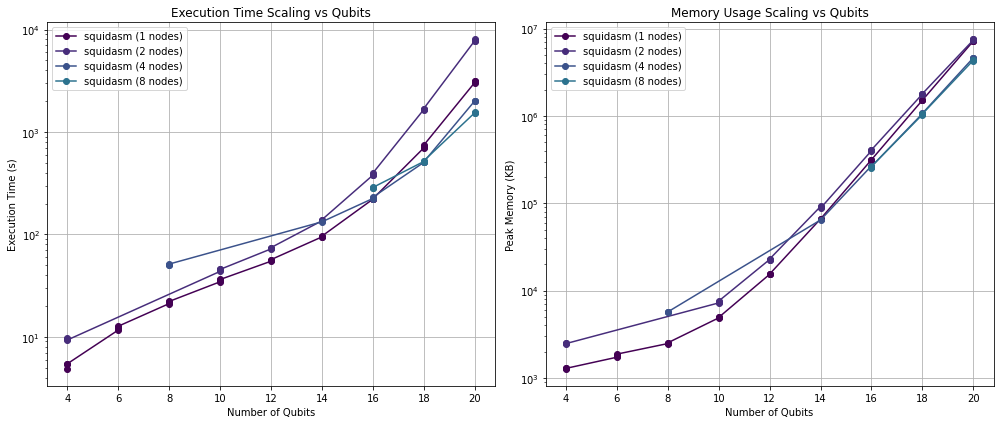

In [9]:
plot_scaling_vs_qubits(df, save_path="benchmark_multi_1.png")

Saved to benchmark_multi_2.png


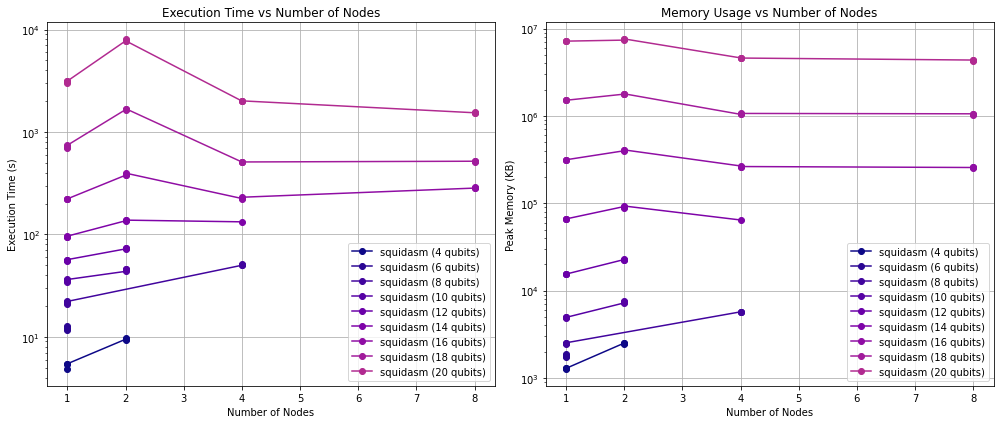

In [10]:
plot_scaling_vs_nodes(df, save_path="benchmark_multi_2.png")

In [16]:
def fidelity_emulator(emulator):

    qubit_values = df["Num Qubits"].unique()
    theta_values = df["Theta"].unique()

    fid_nq = {}
    for nq in sorted(qubit_values):
        fid = []
        for theta in sorted(theta_values):
            result_row1 = df.query(
                "Emulator == @emulator and Nodes == 1 and `Num Qubits` == @nq and Theta == @theta"
            )
            result_row2 = df.query(
                "Emulator == @emulator and Nodes == 2 and `Num Qubits` == @nq and Theta == @theta"
            )

            if not result_row1.empty:
                if not result_row2.empty:
                    counts1 = ast.literal_eval(result_row1.iloc[0]["Result"])
                    counts2 = ast.literal_eval(result_row2.iloc[0]["Result"])
                    fid.append(hellinger_fidelity(counts1, counts2))

        if fid:
            fid_nq[nq]=np.mean(fid)
    return fid_nq


In [14]:
import numpy as np
import ast

def fidelity_vs_monolithic(df, emulator, node_values=None):
    """
    Compute fidelity of distributed simulations (N > 1) against monolithic (N = 1)
    for each number of qubits and theta value.

    Returns:
        dict: fidelity[node_count][num_qubits] = mean fidelity
    """
    qubit_values = sorted(df["Num Qubits"].unique())
    theta_values = sorted(df["Theta"].unique())
    all_node_values = sorted(df["Nodes"].unique())

    # Determine which nodes to compare (exclude 1)
    if node_values is None:
        node_values = [n for n in all_node_values if n != 1]

    fidelity = {}

    for nodes in node_values:
        fid_nq = {}
        for nq in qubit_values:
            fids = []
            for theta in theta_values:
                # Get 1-node result (baseline)
                result1 = df.query(
                    "Emulator == @emulator and Nodes == 1 and `Num Qubits` == @nq and Theta == @theta"
                )
                resultN = df.query(
                    "Emulator == @emulator and Nodes == @nodes and `Num Qubits` == @nq and Theta == @theta"
                )

                if not result1.empty and not resultN.empty:
                    counts1 = ast.literal_eval(result1.iloc[0]["Result"])
                    countsN = ast.literal_eval(resultN.iloc[0]["Result"])
                    fids.append(hellinger_fidelity(counts1, countsN))

            if fids:
                fid_nq[nq] = np.mean(fids)
        if fid_nq:
            fidelity[nodes] = fid_nq

    return fidelity


In [17]:
plt.figure(figsize=(9, 4))

# Define markers for single_node and two_node
markers = {
    1: 'o',  # Circle marker for single_node
    2: 'x'      # Square marker for two_node
}
line_styles = {
    1: 'solid',  # Solid line for single_node
    2: 'dashed'      # Dashed line for two_node
}

# Define colors for each emulator
colors = plt.cm.tab10(range(len(df['Emulator'].unique())))

for emulator in df['Emulator'].unique():
    fid = fidelity_emulator(emulator)
    color = colors[df['Emulator'].unique().tolist().index(emulator)]
    marker = markers[nodes]
    plt.plot(fid.keys(),fid.values(),
                    label=f'{emulator}', color=color, marker=marker)

plt.xlabel('Number of Qubits')
plt.ylabel('Fidelity')
plt.title('Fidelity of distributed QFT vs monolithic QFT')
# plt.yscale('log')
plt.legend()
    
plt.tight_layout()
plt.show()    

plt.savefig('fidelity_v5.png', bbox_inches='tight')


KeyError: 8

<Figure size 648x288 with 0 Axes>

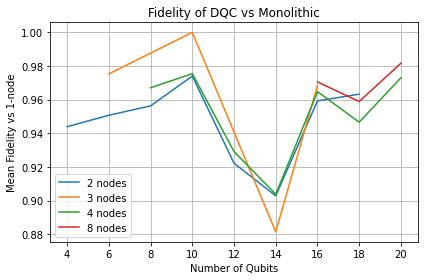

In [15]:
fidelity = fidelity_vs_monolithic(df, emulator="squidasm")

# Plotting (optional)
for nodes, fid_by_nq in fidelity.items():
    plt.plot(sorted(fid_by_nq.keys()), list(fid_by_nq.values()), label=f"{nodes} nodes")

plt.xlabel("Number of Qubits")
plt.ylabel("Mean Fidelity vs 1-node")
plt.title("Fidelity of DQC vs Monolithic")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# def calculate_overhead(df):
#     overhead_data = []

#     for emulator in df['Emulator'].unique():
#         for num_qubits in df['Num Qubits'].unique():
#             single_node_df = df[(df['Emulator'] == emulator) &
#                                 (df['Nodes'] == 1) &
#                                 (df['Num Qubits'] == num_qubits)]
#             two_node_df = df[(df['Emulator'] == emulator) &
#                              (df['Nodes'] == 2) &
#                              (df['Num Qubits'] == num_qubits)]

#             if not single_node_df.empty and not two_node_df.empty:
#                 avg_single_node = single_node_df.mean()
#                 avg_two_node = two_node_df.mean()

#                 time_overhead = avg_two_node['Execution Time (s)'] - avg_single_node['Execution Time (s)']
#                 memory_overhead = avg_two_node['Peak Memory (KB)'] - avg_single_node['Peak Memory (KB)']

#                 time_overhead_percent = (time_overhead / avg_single_node['Execution Time (s)']) * 100
#                 memory_overhead_percent = (memory_overhead / avg_single_node['Peak Memory (KB)']) * 100

#                 overhead_data.append({
#                     'Emulator': emulator,
#                     'Num Qubits': num_qubits,
#                     'Time Overhead (s)': time_overhead,
#                     'Time Overhead (%)': time_overhead_percent,
#                     'Memory Overhead (KB)': memory_overhead,
#                     'Memory Overhead (%)': memory_overhead_percent
#                 })

#     return pd.DataFrame(overhead_data)

In [ ]:
# overhead_df = calculate_overhead(df)
